# England LSOA Demographic Analysis

**Author:** Abdallah Ramadan  
**Dataset:** Office for National Statistics, Census 2021 TS007A

This notebook analyses age structure across 33,755 Lower Layer Super Output
Areas (LSOAs) in England. It develops national and neighbourhood profiles,
estimates median ages from grouped data, compares broad area types and builds
an interpretable demographic segmentation.

The analysis is descriptive. It does not identify the causes of geographic
differences or measure demographic change over time.

## 1. Setup

The notebook uses pandas and NumPy for data preparation, Matplotlib and seaborn
for visualisation, and `pathlib` to locate the repository data reliably.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

Matplotlib is building the font cache; this may take a moment.


## 2. Data loading and validation

The prepared dataset contains one row per English LSOA, identifiers for its
parent geography, total usual residents and counts across 18 five-year age
bands. The validation checks completeness, identifier uniqueness and agreement
between the age-band sum and the recorded total.

In [2]:
def find_project_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / "data" / "raw" / "LSOA_data.csv").exists():
            return candidate
    raise FileNotFoundError("Could not locate data/raw/LSOA_data.csv")


PROJECT_ROOT = find_project_root()
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "LSOA_data.csv"

age_columns = [
    "Age4Under", "Age5to9", "Age10to14", "Age15to19", "Age20to24",
    "Age25to29", "Age30to34", "Age35to39", "Age40to44", "Age45to49",
    "Age50to54", "Age55to59", "Age60to64", "Age65to69", "Age70to74",
    "Age75to79", "Age80to84", "Age85Over",
]

expected_columns = {
    "LSOAName", "LSOACode", "PartOfCode", "PartOfName", "Total", *age_columns
}

lsoa = pd.read_csv(DATA_PATH)

missing_columns = expected_columns.difference(lsoa.columns)
if missing_columns:
    raise ValueError(f"Missing expected columns: {sorted(missing_columns)}")

age_total_difference = lsoa[age_columns].sum(axis=1) - lsoa["Total"]
validation = pd.Series(
    {
        "Rows": len(lsoa),
        "Columns": len(lsoa.columns),
        "Missing cells": int(lsoa.isna().sum().sum()),
        "Duplicated LSOA codes": int(lsoa["LSOACode"].duplicated().sum()),
        "Rows where age counts differ from Total": int(age_total_difference.ne(0).sum()),
        "Population represented": int(lsoa["Total"].sum()),
    },
    name="Value",
)

display(validation.to_frame())
display(lsoa.head())

,Value
Rows,33755
Columns,23
Missing cells,0
Duplicated LSOA codes,0
Rows where age counts differ from Total,0
Population represented,56490091


,LSOAName,LSOACode,PartOfCode,PartOfName,Total,Age4Under,Age5to9,Age10to14,Age15to19,Age20to24,Age25to29,Age30to34,Age35to39,Age40to44,Age45to49,Age50to54,Age55to59,Age60to64,Age65to69,Age70to74,Age75to79,Age80to84,Age85Over
0,City of London 001A,E01000001,E09000001,City of London,1473,52,34,32,23,90,159,132,117,114,105,89,73,83,119,102,57,57,35
1,City of London 001B,E01000002,E09000001,City of London,1384,33,24,22,31,100,166,134,110,92,98,122,88,87,76,69,59,43,30
2,City of London 001C,E01000003,E09000001,City of London,1613,39,32,33,23,96,187,166,144,111,113,155,118,111,86,85,50,31,33
3,City of London 001E,E01000005,E09000001,City of London,1101,52,45,35,89,118,97,118,88,61,58,87,82,67,35,26,17,14,12
4,Barking and Dagenham 016A,E01000006,E09000002,Barking and Dagenham,1842,153,127,110,122,124,130,174,151,164,153,121,85,70,66,41,18,17,16


The file contains 33,755 unique LSOAs and 56,490,091 residents. No missing
cells or duplicated LSOA codes are present, and every row's age-band counts sum
to its recorded total.

## 3. National and selected-neighbourhood age profiles

### 3.1 England age profile

Counts are aggregated across all LSOAs and divided by the total population to
produce the national proportion in each age band.

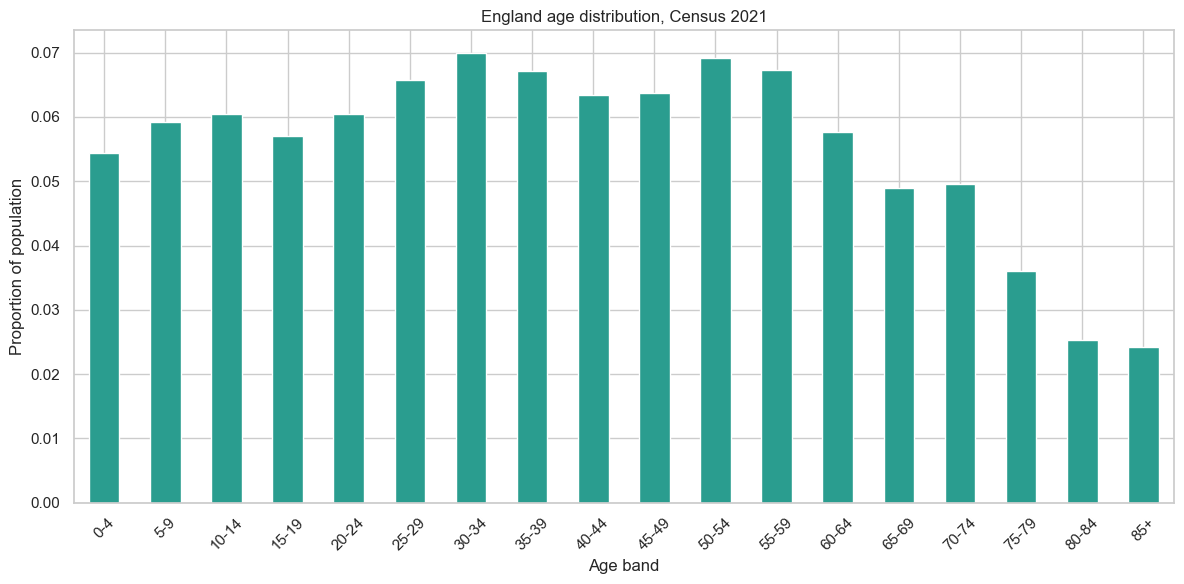

,Proportion
30-34,0.069971
50-54,0.069177
55-59,0.067379
35-39,0.067186
25-29,0.065771


In [3]:
age_labels = [
    "0-4", "5-9", "10-14", "15-19", "20-24", "25-29", "30-34",
    "35-39", "40-44", "45-49", "50-54", "55-59", "60-64", "65-69",
    "70-74", "75-79", "80-84", "85+",
]

england_counts = lsoa[age_columns].sum()
england_proportions = england_counts / england_counts.sum()
england_proportions.index = age_labels

ax = england_proportions.plot(kind="bar", color="#2a9d8f", figsize=(12, 6))
ax.set(
    title="England age distribution, Census 2021",
    xlabel="Age band",
    ylabel="Proportion of population",
)
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

england_proportions.sort_values(ascending=False).head().to_frame("Proportion")

The 30-to-34 group is the largest individual band at approximately 7.0% of the
analysed population. Several working-age bands have similar proportions, while
the oldest groups account for smaller shares.

### 3.2 Selected LSOAs compared with England

The three example LSOAs illustrate how local age profiles can differ markedly
from the national distribution. Proportions are used so areas with different
population totals remain comparable.

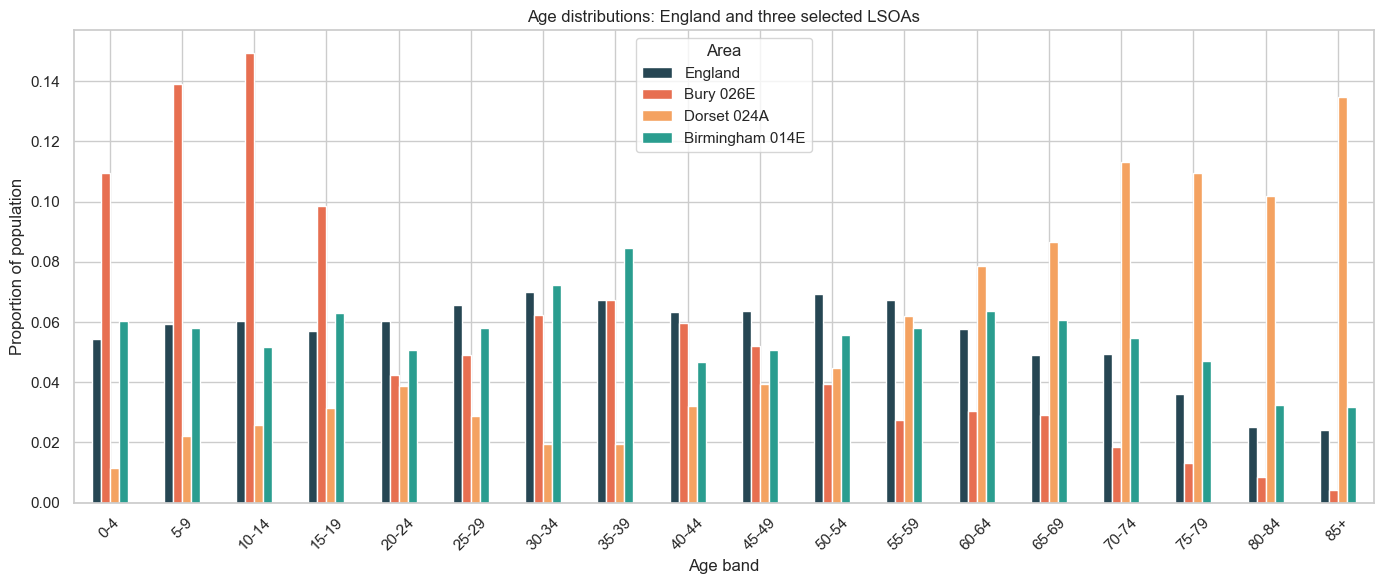

In [4]:
selected_areas = {
    "E01005044": "Bury 026E",
    "E01020395": "Dorset 024A",
    "E01009136": "Birmingham 014E",
}

comparison = pd.DataFrame({"England": england_proportions.to_numpy()}, index=age_labels)

for code_value, label in selected_areas.items():
    row = lsoa.loc[lsoa["LSOACode"].eq(code_value)].iloc[0]
    comparison[label] = row[age_columns].to_numpy(dtype=float) / row["Total"]

ax = comparison.plot(
    kind="bar",
    figsize=(14, 6),
    color=["#264653", "#e76f51", "#f4a261", "#2a9d8f"],
)
ax.set(
    title="Age distributions: England and three selected LSOAs",
    xlabel="Age band",
    ylabel="Proportion of population",
)
ax.tick_params(axis="x", rotation=45)
ax.legend(title="Area")
plt.tight_layout()
plt.show()

Bury 026E has a much larger share of residents below age 20 than the national
profile, while Dorset 024A has a much larger share aged 65 and over.
Birmingham 014E is closer to the national shape. These contrasts describe the
selected areas only; explaining them would require additional housing,
education, migration and economic data.

## 4. Neighbourhood indicators and grouped median age

In [5]:
younger_columns = ["Age4Under", "Age5to9", "Age10to14", "Age15to19"]
older_columns = ["Age65to69", "Age70to74", "Age75to79", "Age80to84", "Age85Over"]

lsoa["younger_proportion"] = lsoa[younger_columns].sum(axis=1) / lsoa["Total"]
lsoa["older_proportion"] = lsoa[older_columns].sum(axis=1) / lsoa["Total"]

lsoa[["younger_proportion", "older_proportion"]].describe()

,younger_proportion,older_proportion
count,33755.000000,33755.000000
mean,0.227832,0.189168
std,0.055301,0.085520
min,0.018081,0.000736
25%,0.192297,0.123995
50%,0.223183,0.182751
75%,0.258689,0.246851
max,0.628793,0.655409


Median age is estimated from grouped counts by locating the age band where the
cumulative population reaches 50% and interpolating within that five-year
band. This produces a useful approximation, not an exact individual-level
median.

In [6]:
lower_age_boundaries = np.arange(0, 90, 5)


def median_from_counts(counts):
    counts = np.asarray(counts, dtype=float)
    total = counts.sum()
    if total <= 0:
        return np.nan

    cumulative = counts.cumsum() / total
    index = int(np.argmax(cumulative >= 0.5))
    previous_fraction = 0.0 if index == 0 else cumulative[index - 1]
    band_fraction = cumulative[index] - previous_fraction

    if band_fraction <= 0:
        return float(lower_age_boundaries[index])

    return lower_age_boundaries[index] + 5 * (
        (0.5 - previous_fraction) / band_fraction
    )


lsoa["median_age"] = lsoa[age_columns].apply(median_from_counts, axis=1)

lsoa[["younger_proportion", "older_proportion", "median_age"]].describe()

,younger_proportion,older_proportion,median_age
count,33755.000000,33755.000000,33755.000000
mean,0.227832,0.189168,42.032147
std,0.055301,0.085520,7.782742
min,0.018081,0.000736,14.530516
25%,0.192297,0.123995,36.128752
50%,0.223183,0.182751,41.460674
75%,0.258689,0.246851,47.821934
max,0.628793,0.655409,71.875000


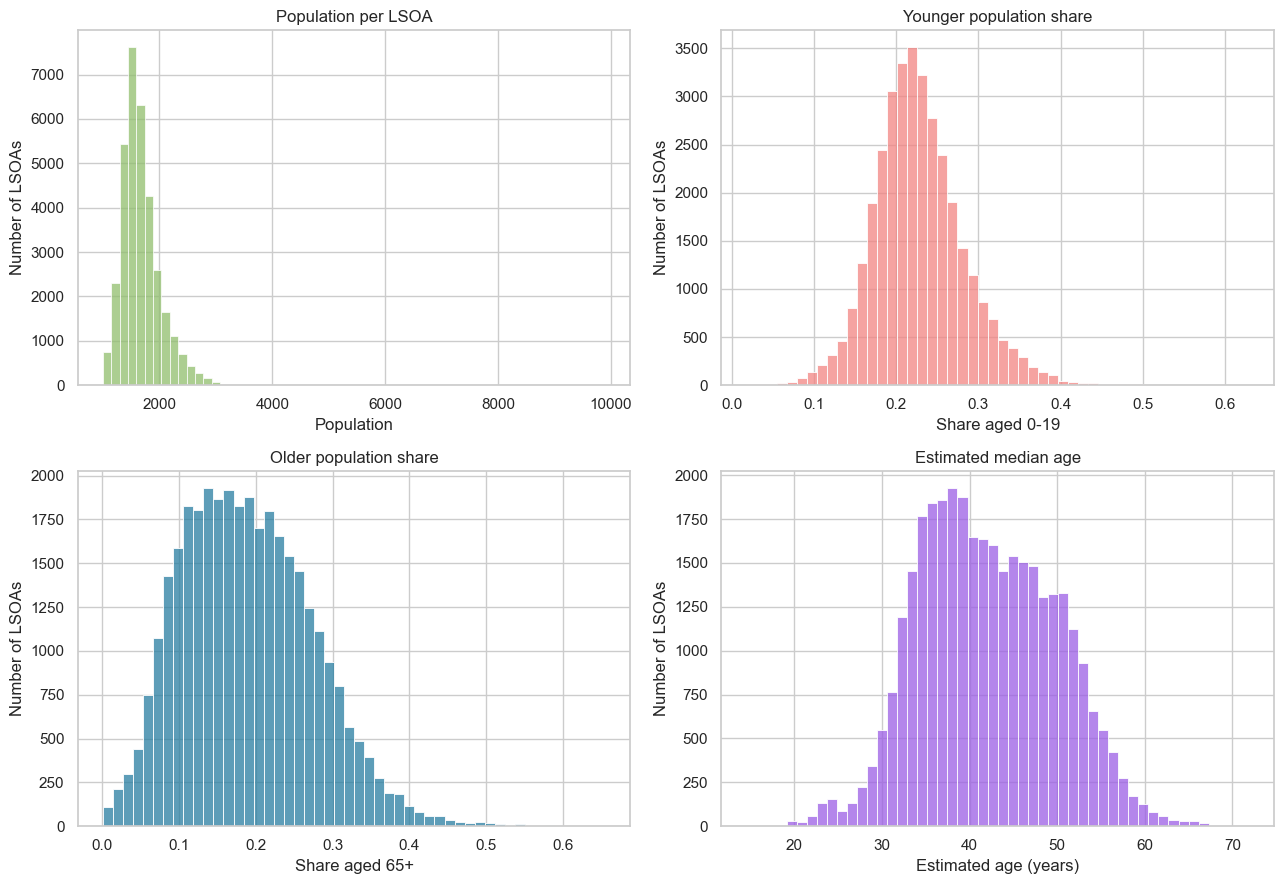

,Skewness
Total,2.057918
younger_proportion,0.609356
older_proportion,0.477605
median_age,0.156343


In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

sns.histplot(lsoa["Total"], bins=60, color="#90be6d", ax=axes[0, 0])
axes[0, 0].set(title="Population per LSOA", xlabel="Population")

sns.histplot(lsoa["younger_proportion"], bins=50, color="#f28482", ax=axes[0, 1])
axes[0, 1].set(title="Younger population share", xlabel="Share aged 0-19")

sns.histplot(lsoa["older_proportion"], bins=50, color="#277da1", ax=axes[1, 0])
axes[1, 0].set(title="Older population share", xlabel="Share aged 65+")

sns.histplot(lsoa["median_age"], bins=50, color="#9b5de5", ax=axes[1, 1])
axes[1, 1].set(title="Estimated median age", xlabel="Estimated age (years)")

for ax in axes.flat:
    ax.set_ylabel("Number of LSOAs")

plt.tight_layout()
plt.show()

lsoa[["Total", "younger_proportion", "older_proportion", "median_age"]].skew().to_frame("Skewness")

LSOA population size is strongly right-skewed. The younger and older shares are
mildly right-skewed, while the estimated median-age distribution is close to
symmetric with a small positive skew. The distributions also contain genuine
neighbourhood extremes that motivate the segmentation below.

## 5. National and neighbourhood median comparison

In [8]:
england_median_age = median_from_counts(england_counts)
median_of_lsoa_medians = lsoa["median_age"].median()

median_comparison = pd.Series(
    {
        "Grouped national median-age estimate": england_median_age,
        "Median of LSOA median-age estimates": median_of_lsoa_medians,
    },
    name="Years",
)

median_comparison.to_frame().round(2)

,Years
Grouped national median-age estimate,40.43
Median of LSOA median-age estimates,41.46


The grouped national estimate is approximately 40.43 years, compared with
41.46 years for the median of the LSOA estimates. The national calculation
weights every resident equally. The second calculation gives each LSOA equal
weight, regardless of its population size.

## 6. Estimated median age by area type

,LSOAs,Median,Mean,Standard_deviation
area_type,,,,
London borough,4994,36.15,36.80,4.59
Metropolitan district,7335,39.97,40.23,7.49
Unitary authority,8827,42.28,42.53,7.99
Non-metropolitan district,12599,45.05,44.80,7.48


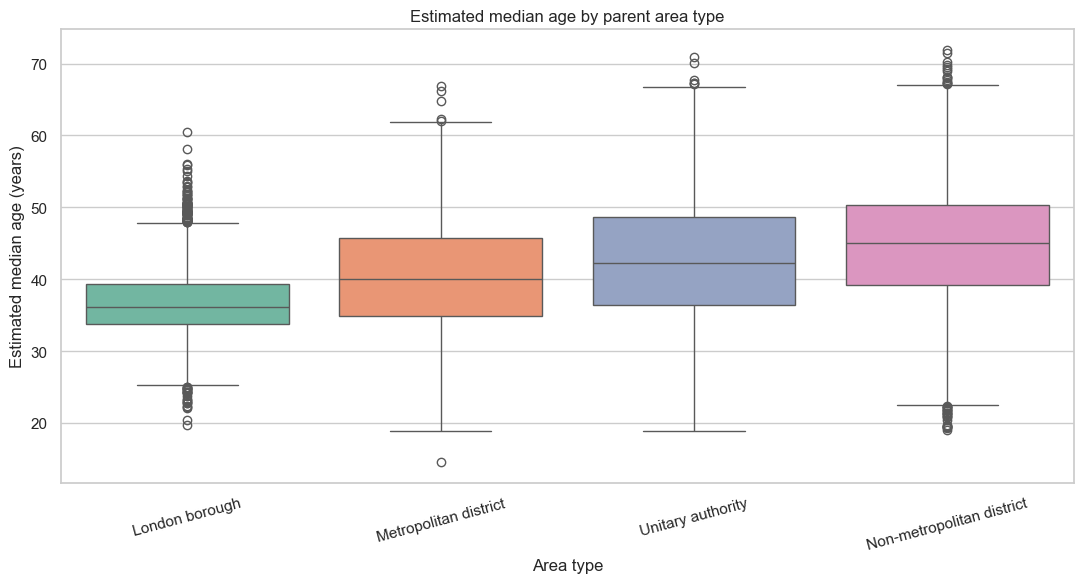

In [9]:
area_type_map = {
    "E06": "Unitary authority",
    "E07": "Non-metropolitan district",
    "E08": "Metropolitan district",
    "E09": "London borough",
}
area_order = [
    "London borough",
    "Metropolitan district",
    "Unitary authority",
    "Non-metropolitan district",
]

lsoa["area_type"] = lsoa["PartOfCode"].str[:3].map(area_type_map)
if lsoa["area_type"].isna().any():
    raise ValueError("One or more parent-geography codes could not be classified")

area_summary = (
    lsoa.groupby("area_type")["median_age"]
    .agg(LSOAs="count", Median="median", Mean="mean", Standard_deviation="std")
    .reindex(area_order)
)
display(area_summary.round(2))

plt.figure(figsize=(11, 6))
sns.boxplot(
    data=lsoa,
    x="area_type",
    y="median_age",
    hue="area_type",
    order=area_order,
    palette="Set2",
    legend=False,
)
plt.title("Estimated median age by parent area type")
plt.xlabel("Area type")
plt.ylabel("Estimated median age (years)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

The median estimated age rises from 36.15 years in London-borough LSOAs to
45.05 years in non-metropolitan-district LSOAs. These are descriptive
differences between broad categories; the analysis does not establish why the
distributions differ.

## 7. Exploratory demographic segmentation

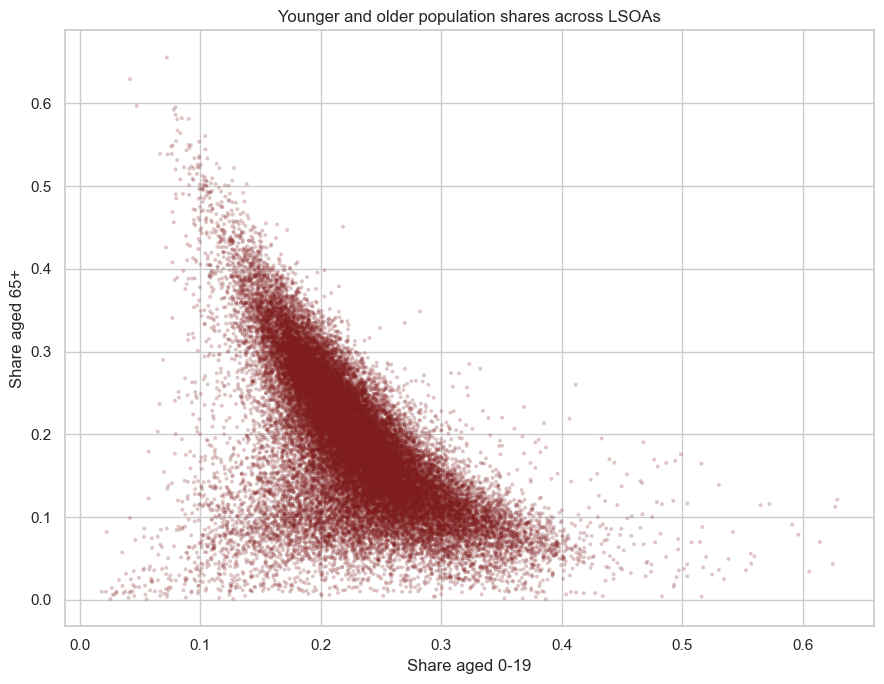

In [10]:
plt.figure(figsize=(9, 7))
plt.scatter(
    lsoa["younger_proportion"],
    lsoa["older_proportion"],
    s=8,
    alpha=0.25,
    color="#7f1d1d",
    edgecolors="none",
)
plt.title("Younger and older population shares across LSOAs")
plt.xlabel("Share aged 0-19")
plt.ylabel("Share aged 65+")
plt.tight_layout()
plt.show()

The scatter plot has a broad triangular form. Many LSOAs sit near the centre,
while the corners contain areas with unusually high younger shares, unusually
high older shares, or low values for both groups. A low value for both groups
implies that a larger share lies between ages 20 and 64.

The following rules use dataset quartiles to create transparent exploratory
labels. They are not official classifications.

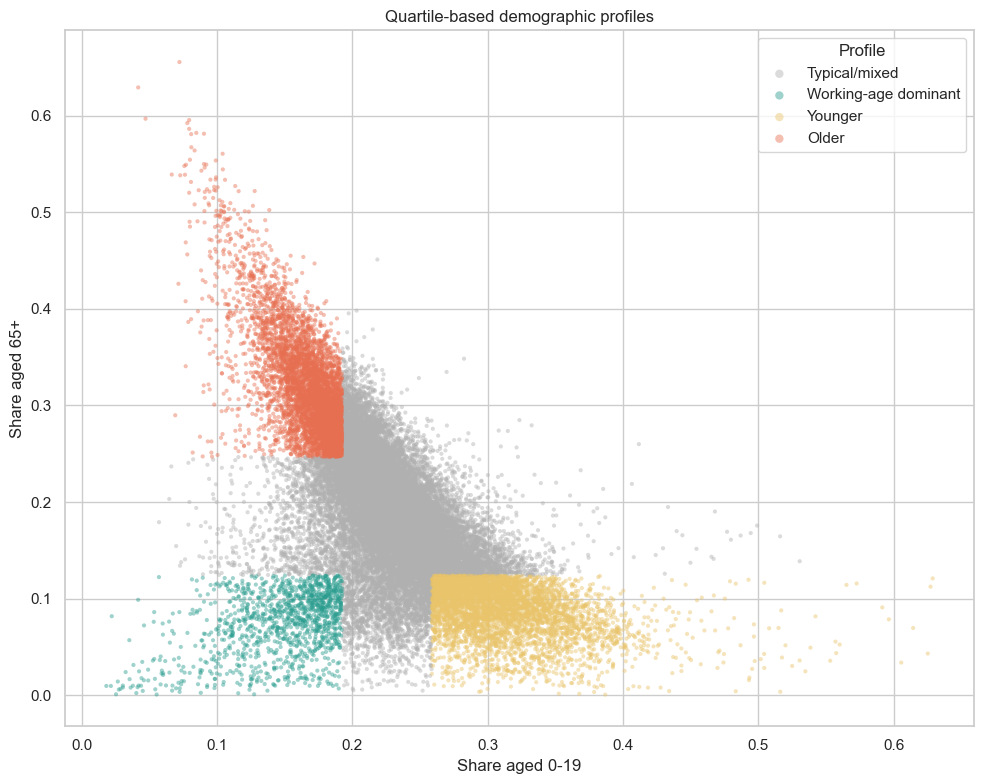

In [11]:
young_q1, young_q3 = lsoa["younger_proportion"].quantile([0.25, 0.75])
old_q1, old_q3 = lsoa["older_proportion"].quantile([0.25, 0.75])

conditions = [
    (lsoa["younger_proportion"] >= young_q3) & (lsoa["older_proportion"] <= old_q1),
    (lsoa["older_proportion"] >= old_q3) & (lsoa["younger_proportion"] <= young_q1),
    (lsoa["younger_proportion"] <= young_q1) & (lsoa["older_proportion"] <= old_q1),
]
labels = ["Younger", "Older", "Working-age dominant"]
lsoa["age_profile"] = np.select(conditions, labels, default="Typical/mixed")

profile_order = ["Typical/mixed", "Working-age dominant", "Younger", "Older"]
profile_colours = {
    "Typical/mixed": "#b0b0b0",
    "Working-age dominant": "#2a9d8f",
    "Younger": "#e9c46a",
    "Older": "#e76f51",
}

plt.figure(figsize=(10, 8))
for label in profile_order:
    subset = lsoa.loc[lsoa["age_profile"].eq(label)]
    plt.scatter(
        subset["younger_proportion"],
        subset["older_proportion"],
        s=9,
        alpha=0.45,
        label=label,
        color=profile_colours[label],
        edgecolors="none",
    )

plt.title("Quartile-based demographic profiles")
plt.xlabel("Share aged 0-19")
plt.ylabel("Share aged 65+")
plt.legend(title="Profile", markerscale=2)
plt.tight_layout()
plt.show()

### 7.1 Profile composition by area type

age_profile,Typical/mixed,Working-age dominant,Younger,Older
area_type,,,,
London borough,3098,662,1186,48
Metropolitan district,4961,219,1382,773
Unitary authority,5729,239,1305,1554
Non-metropolitan district,8496,140,1001,2962


age_profile,Typical/mixed,Working-age dominant,Younger,Older
area_type,,,,
London borough,62.0,13.3,23.7,1.0
Metropolitan district,67.6,3.0,18.8,10.5
Unitary authority,64.9,2.7,14.8,17.6
Non-metropolitan district,67.4,1.1,7.9,23.5


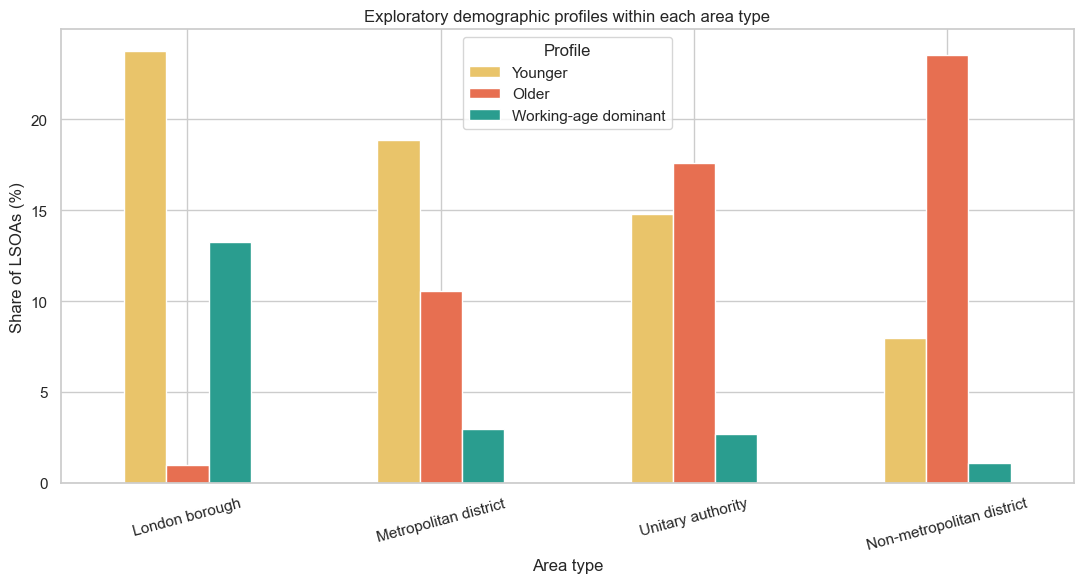

In [12]:
profile_counts = pd.crosstab(lsoa["area_type"], lsoa["age_profile"]).reindex(area_order)
profile_shares = profile_counts.div(profile_counts.sum(axis=1), axis=0) * 100

display(profile_counts[profile_order])
display(profile_shares[profile_order].round(1))

distinctive_profiles = ["Younger", "Older", "Working-age dominant"]
ax = profile_shares[distinctive_profiles].plot(
    kind="bar",
    figsize=(11, 6),
    color=[profile_colours[label] for label in distinctive_profiles],
)
ax.set(
    title="Exploratory demographic profiles within each area type",
    xlabel="Area type",
    ylabel="Share of LSOAs (%)",
)
ax.tick_params(axis="x", rotation=15)
ax.legend(title="Profile")
plt.tight_layout()
plt.show()

Percentage shares provide a fairer comparison than raw counts because the four
area types contain different numbers of LSOAs. Under these rules:

- 23.7% of London-borough LSOAs are labelled **Younger**, compared with 7.9%
  of non-metropolitan-district LSOAs.
- 23.5% of non-metropolitan-district LSOAs are labelled **Older**, compared
  with 1.0% of London-borough LSOAs.
- 13.3% of London-borough LSOAs are labelled **Working-age dominant**, the
  largest share among the four categories.

The labels summarise relative patterns within this dataset and should not be
treated as fixed demographic definitions.

## 8. Conclusions and limitations

The analysis demonstrates substantial variation in age structure across
English neighbourhoods. London-borough LSOAs have the lowest median estimated
age as a group, while non-metropolitan-district LSOAs have the highest. The
quartile rules also reveal contrasting concentrations of younger, older and
working-age-dominant profiles.

Important limitations:

- the data describe one census date and cannot measure change over time;
- median ages are approximated from five-year grouped counts;
- area-type comparisons do not control for housing, universities, migration,
  employment, urbanisation or other possible explanatory variables;
- the quartile classification is exploratory and dataset-dependent; and
- Census outputs apply statistical disclosure controls, so small count
  differences can occur between published tables.

Future work could add mapping, use model-based clustering, examine spatial
autocorrelation or compare multiple census years using harmonised boundaries.